# Градиентный бустинг над деревьями

Учебный ноутбук по материалам семинара № 9 «Градиентный бустинг» (ФКН ВШЭ) и обсуждения функционального градиентного спуска.

**Цель:** понять, почему модель складывает деревья, что означает псевдоостаток, как выбор функции потерь меняет обучение и чем бустинг отличается от случайного леса.

## Содержание
1. [Идея и сумма моделей](#1-идея-и-сумма-моделей)
2. [Антиградиент и скалярное произведение](#2-антиградиент-и-скалярное-произведение)
3. [Потери и псевдоостатки](#3-потери-и-псевдоостатки)
4. [Алгоритм и пример на Python](#4-алгоритм-и-пример-на-python)
5. [Глубина деревьев и контроль переобучения](#5-глубина-деревьев-и-контроль-переобучения)
6. [Бустинг и случайный лес: сложность](#6-бустинг-и-случайный-лес-сложность)
7. [XGBoost, LightGBM, CatBoost](#7-xgboost-lightgbm-catboost)
8. [Как библиотеки выращивают деревья](#8-как-библиотеки-выращивают-деревья)

## 1. Идея и сумма моделей

Пусть есть пары $(x_i,y_i)$ и функция потерь $L(y,z)$, где $z$ — **числовой выход модели**. Минимизируем эмпирический риск:

$$Q(F)=\frac1n\sum_{i=1}^n L(y_i,F(x_i)).$$

Начинаем с простой константы $F_0(x)=\arg\min_c\sum_i L(y_i,c)$. Для квадратичной потери $L(y,z)=\tfrac12(y-z)^2$ это среднее $\bar y$.

На каждом шаге добавляем дерево как поправку:

$$F_m(x)=F_{m-1}(x)+\eta\gamma_m h_m(x),\qquad
F_M(x)=F_0(x)+\sum_{m=1}^M\eta\gamma_m h_m(x).$$

Здесь $\eta$ — темп обучения, а $\gamma_m$ — возможная оптимальная длина шага. Если она не подбирается отдельно, её эффект можно включить в значения листьев. Например, базовый прогноз 100 и поправки $+20,-5,+2$ дают 117. Дерево учится исправлять текущую композицию, поэтому возникает **сумма**.

## 2. Антиградиент и скалярное произведение

На обучающей выборке значения функции образуют вектор $\mathbf f=(F(x_1),\dots,F(x_n))$. Для $Q=\frac1n\sum_iL(y_i,f_i)$ производная по координате равна $\partial Q/\partial f_i=\frac1n\partial L(y_i,f_i)/\partial f_i$.

Если положить $g_i=\partial L(y_i,f_i)/\partial f_i$ и определить скалярное произведение $\langle u,v\rangle_n=\frac1n\sum_i u_iv_i$, то малое добавление $\varepsilon h$ даёт

$$Q(F+\varepsilon h)\approx Q(F)+\varepsilon\langle g,h\rangle_n.$$

Направление $h=-g$ уменьшает риск в первом приближении: $\langle g,-g\rangle_n=-\|g\|_n^2$. Поэтому цели для нового дерева — **псевдоостатки**

$$s_i=-\left.\frac{\partial L(y_i,z)}{\partial z}\right|_{z=F_{m-1}(x_i)}.$$

Множитель $1/n$ уже учтён в скалярном произведении: так не возникает противоречия между градиентом среднего риска и формулой для $s_i$. На конечной выборке хватает производных по $n$ числам. Производная Фреше нужна для строгой записи, когда аргумент риска — целая функция: $Q(F+h)=Q(F)+DQ[F](h)+o(\|h\|)$, причём в подходящем гильбертовом пространстве $DQ[F](h)=\langle\nabla Q(F),h\rangle$. Для вычисления алгоритма знать теорему Фреше не требуется.

**Оговорка:** направление самого быстрого спуска зависит от выбранной нормы и скалярного произведения. Дерево лишь приближает антиградиент, поэтому его добавление без подходящего шага не обязано уменьшать риск.

## 3. Потери и псевдоостатки

| Задача и потеря | $s=-\partial L/\partial z$ | Что означает |
|---|---|---|
| MSE, $\tfrac12(y-z)^2$ | $y-z$ | Величина обычной ошибки |
| MAE, $|y-z|$ | $\operatorname{sign}(y-z)$ | Направление исправления; в $z=y$ берут субградиент |
| Бинарная log-loss, $y\in\{0,1\}$, $L=-y\log p-(1-y)\log(1-p)$, $p=\sigma(z)$ | $y-p$ | Разность между меткой и вероятностью; $z$ — логит |

**Почему не всегда $y-z$?** Это антиградиент только для выбранной квадратичной потери (с указанным множителем $1/2$). При асимметричной потере из семинара завышение на 5 штрафуется в десять раз сильнее занижения на 5; антиградиенты равны $-50$ и $+5$. Обычные остатки $-5$ и $+5$ игнорировали бы этот приоритет.

MSE подходит, когда большие ошибки нужно штрафовать сильнее. При выбросах рассматривают Huber или MAE; для квантилей — квантильную потерю; для бинарной классификации — log-loss. Если функция недифференцируема, формула обычного градиента не действует в точках излома: требуется выбор субградиента или специальная процедура.

**Две разные квадратичные задачи:** исходный риск может быть log-loss, а дерево на очередном шаге обучают приближать числа $s_i$ по $\sum_i(s_i-h(x_i))^2$. Это способ подобрать направление в пространстве предсказаний, а не замена исходной цели. Затем шаг или прогнозы листьев можно подбирать по исходной потере.

In [1]:
import numpy as np

y = np.array([10., 20., 30.])
pred = np.array([12., 15., 25.])
s = y - pred  # MSE: антиградиент без общего множителя 1/n
print("Текущий прогноз:", pred)
print("Псевдоостатки:", s)
print("Прогноз после точного шага:", pred + s)

Текущий прогноз: [12. 15. 25.]
Псевдоостатки: [-2.  5.  5.]
Прогноз после точного шага: [10. 20. 30.]


### 3.1. Упражнение: один шаг бустинга с асимметричной потерей

Рассмотрим функцию потерь, в которой завышение прогноза штрафуется в 10 раз сильнее занижения:

$$L(y,z)=\frac12\left(10\,\mathbb{1}[z\ge y]+\mathbb{1}[z<y]\right)(y-z)^2.$$

Здесь $\mathbb{1}[\text{условие}]$ равно 1, если условие выполнено, и 0 иначе. Возьмём выборку:

| $i$ | $x_i$ | $y_i$ |
|---:|---:|---:|
| 1 | 1 | 0 |
| 2 | 2 | 1 |
| 3 | 3 | 4 |
| 4 | 4 | 5 |

**Задание.** Найдите начальную константу $F_0$, псевдоостатки, лучшее разбиение пня глубины 1 по SSE и оптимальные значения его листьев.

#### Решение. Шаг 1: начальная константа

Ищем $F_0(x)=c$, минимизирующую $\sum_iL(y_i,c)$. При $0\le c<1$ прогноз завышен только для $y_1=0$. Производная суммарной потери равна

$$10(c-0)+(c-1)+(c-4)+(c-5)=13c-10.$$

Следовательно,

$$F_0(x)=\frac{10}{13}\approx0.769.$$

Корень действительно лежит в $[0,1)$; выпуклость потери гарантирует глобальный минимум. Из-за асимметрии начальный прогноз не равен среднему $\bar y=2.5$.

#### Шаг 2: псевдоостатки

Производная и антиградиент по текущему прогнозу $z$ имеют вид

$$\frac{\partial L}{\partial z}=\begin{cases}10(z-y),&z\ge y,\\z-y,&z<y,\end{cases}\qquad r=-\frac{\partial L}{\partial z}=\begin{cases}10(y-z),&z\ge y,\\y-z,&z<y.\end{cases}$$

Подставляем $z=F_0=10/13$:

| $x_i$ | $y_i$ | Ветвь потери | Псевдоостаток $r_i$ |
|---:|---:|---|---:|
| 1 | 0 | $z\ge y$ | $-100/13\approx-7.692$ |
| 2 | 1 | $z<y$ | $3/13\approx0.231$ |
| 3 | 4 | $z<y$ | $42/13\approx3.231$ |
| 4 | 5 | $z<y$ | $55/13\approx4.231$ |

Именно здесь исходная функция потерь влияет на шаг бустинга. Обычный остаток первого объекта равнялся бы $-10/13$, но асимметричная потеря превращает его в $-100/13$.

#### Шаг 3: строим дерево по обычному SSE

Числа $r_i$ становятся новым непрерывным таргетом дерева. Для каждого порога $t$ дерево минимизирует обычную сумму квадратов ошибок:

$$SSE(t)=\sum_{i\in R_L}(r_i-\bar r_L)^2+\sum_{i\in R_R}(r_i-\bar r_R)^2.$$

| Порог $t$ | Среднее слева $\bar r_L$ | Среднее справа $\bar r_R$ | $SSE(t)$ |
|---:|---:|---:|---:|
| 1.5 | $-100/13=-7.692$ | $100/39=2.564$ | **8.667** |
| 2.5 | $-97/26=-3.731$ | $97/26=3.731$ | 31.888 |
| 3.5 | $-55/39=-1.410$ | $55/13=4.231$ | 63.696 |

Лучшее разбиение — $x<1.5$. Оно выбрано по **SSE псевдоостатков**, хотя исходная потеря не является обычным MSE. Деление SSE на число объектов даёт MSE и не меняет выбор порога.

#### Шаг 4: оптимизируем прогнозы листьев по исходной потере

Средние псевдоостатков были нужны для выбора структуры дерева. После этого добавку $\gamma_j$ в каждом листе можно найти уже по исходной функции потерь:

$$\gamma_j=\arg\min_\gamma\sum_{x_i\in R_j}L\left(y_i,F_0(x_i)+\gamma\right).$$

В левом листе находится только $y_1=0$, поэтому оптимальный новый прогноз равен 0 и $\gamma_L=-10/13$. В правом листе $y=(1,4,5)$. Оптимум лежит между 1 и 4, поэтому

$$10(z-1)+(z-4)+(z-5)=0,\qquad z_R=\frac{19}{12},\qquad \gamma_R=\frac{19}{12}-\frac{10}{13}=\frac{127}{156}.$$

При $\eta=1$ после первого дерева получаем

$$F_1(x)=\begin{cases}0,&x<1.5,\\19/12,&x\ge1.5.\end{cases}$$

Суммарная исходная потеря уменьшилась:

$$Q(F_0)=\frac{2899}{169}\approx17.154,\qquad Q(F_1)=\frac{251}{24}\approx10.458.$$

#### Главный вывод

В классическом gradient boosting выполняются две разные оптимизации:

1. **Исходная $L(y,z)$** определяет псевдоостатки и оптимальные значения листьев или длину шага.
2. **Регрессионное дерево** аппроксимирует уже вычисленные псевдоостатки и выбирает структуру по обычному MSE/SSE.

Поэтому дерево, обученное по MSE, не заставляет весь бустинг оптимизировать MSE по исходным $y$. MSE здесь является вспомогательным критерием приближения антиградиента.

> **Оговорка.** Это классическая first-order формулировка. XGBoost и LightGBM обычно оценивают разбиения по суммам градиентов и гессианов, поэтому утверждение «любая реализация буквально строит каждое дерево по MSE» не универсально.

## 4. Алгоритм и пример на Python

1. Выбрать $F_0$ (для MSE — среднее ответов).
2. Посчитать $s_i$ по **исходной** функции потерь при текущих прогнозах.
3. Обучить небольшое регрессионное дерево $h_m(x_i)\approx s_i$.
4. При необходимости найти $\gamma_m=\arg\min_\gamma\sum_i L(y_i,F_{m-1}(x_i)+\gamma h_m(x_i))$ или оптимизировать значения листьев.
5. Обновить $F_m=F_{m-1}+\eta\gamma_m h_m$, повторить и оценить качество на отложенной выборке.

Следующий код реализует только простой вариант для MSE с фиксированным $\eta$. Дерево обучается на остатках; это помогает увидеть сумму моделей без деталей промышленных библиотек.

F0 = -0.036; после 30 деревьев: train MSE = 0.022, validation MSE = 0.057


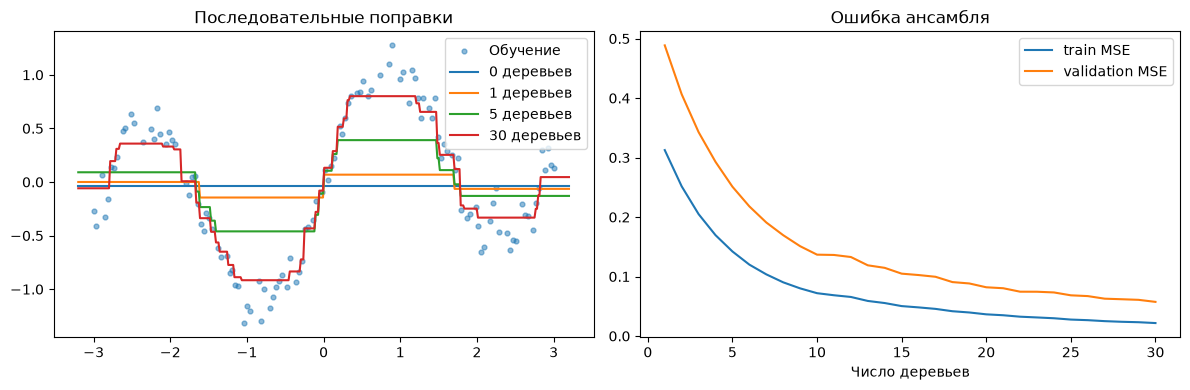

In [2]:
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

rng = np.random.default_rng(42)
X = np.linspace(-3, 3, 160).reshape(-1, 1)
y = np.sin(2 * X[:, 0]) + 0.2 * X[:, 0] + rng.normal(0, 0.16, len(X))
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.25, random_state=42)

initial = float(y_train.mean())
train_pred = np.full(len(X_train), initial)
val_pred = np.full(len(X_val), initial)
eta = 0.15
trees = []
history = []
for step in range(30):
    residual = y_train - train_pred
    tree = DecisionTreeRegressor(max_depth=2, min_samples_leaf=5, random_state=step)
    tree.fit(X_train, residual)
    trees.append(tree)
    train_pred += eta * tree.predict(X_train)
    val_pred += eta * tree.predict(X_val)
    history.append((mean_squared_error(y_train, train_pred),
                    mean_squared_error(y_val, val_pred)))

print(f"F0 = {initial:.3f}; после 30 деревьев: train MSE = {history[-1][0]:.3f}, validation MSE = {history[-1][1]:.3f}")

grid = np.linspace(-3.2, 3.2, 400).reshape(-1, 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(X_train[:, 0], y_train, s=12, alpha=.5, label="Обучение")
for count in [0, 1, 5, 30]:
    curve = initial + eta * sum((tree.predict(grid) for tree in trees[:count]), np.zeros(len(grid)))
    axes[0].plot(grid[:, 0], curve, label=f"{count} деревьев")
axes[0].legend(); axes[0].set_title("Последовательные поправки")
axes[1].plot(np.arange(1, 31), history)
axes[1].legend(["train MSE", "validation MSE"])
axes[1].set_xlabel("Число деревьев"); axes[1].set_title("Ошибка ансамбля")
plt.tight_layout(); plt.show()

## 5. Глубина деревьев и контроль переобучения

Неглубокое дерево даёт простую поправку: оно захватывает несколько основных разбиений, а следующие деревья постепенно уточняют результат. Малое $\eta$ снижает влияние каждого шага; число деревьев и глубину подбирают по валидации, часто с ранней остановкой. Глубокое дерево может быстро подогнать остатки вместе с шумом и обычно дороже при обучении и предсказании.

Это **не правило «всегда глубина 2»**: для сложных взаимодействий нужны более глубокие деревья. Достаточная глубина зависит от данных, размера выборки, ограничения листьев и регуляризации. Для корректной оценки ранней остановки используют валидацию, а не тестовую выборку. Ансамбль деревьев также обычно не продолжает линейный тренд за пределы значений признака, встречавшихся при обучении.

## 6. Бустинг и случайный лес: сложность

Обозначим $n$ — число объектов, $d$ — число проверяемых признаков, $D$ — максимальная глубина дерева, $M$ — число деревьев. В идеализированной схеме после подготовки кандидатов поиск лучшего порога по одному признаку в узле занимает $O(n_{узла})$: статистики обновляют за один проход. На одном уровне сумма объектов по узлам не превышает $n$, поэтому стоимость дерева $O(Ddn)$.

| Операция | Бустинг | Случайный лес |
|---|---:|---:|
| Обучение, последовательная сумма работы | $O(MDdn)$ | $O(MDfn)$, где $f\le d$ признаков пробуют в узле |
| Прогноз одного объекта | $O(MD)$ | $O(MD)$ |
| Память на деревья | $O(M2^D)$ в грубой верхней оценке | $O(M2^D)$ |

Для леса bootstrap обычно берёт порядка $n$ строк на дерево; при $f=d$ и одинаковых $M,D$ **оценки общего объёма работы одного порядка**. Фактические $D$, $M$, $f$ и стоимость разбиения часто различаются. Лес может строить деревья параллельно, а бустинг зависит от предыдущих деревьев. Поэтому одинаковый Big O не означает одинаковое время работы.

**Условия оценки:** сортировка непрерывных значений или построение гистограмм добавляет собственную стоимость (например, первоначальная сортировка порядка $O(dn\log n)$ в простой схеме). Наивный пересчёт всех порогов и некоторые реализации дают другие оценки. Память $O(M2^D)$ — грубый верхний предел числа узлов, а не типичный размер модели.

## 7. XGBoost, LightGBM, CatBoost

Три популярные библиотеки реализуют деревья с градиентным бустингом, но используют разные инженерные решения. `scikit-learn` (`GradientBoostingRegressor`, `HistGradientBoostingRegressor`) удобен как учебная основа и базовая модель.

| Библиотека | Основной акцент | Практический ориентир |
|---|---|---|
| **XGBoost** | Регуляризация дерева и весов листьев, градиенты и вторые производные; гистограммный поиск разбиений (`hist`) | Гибкие настройки, в том числе регуляризация и работа с пропусками; начать с ограниченной глубины |
| **LightGBM** | Гистограммы и рост по листу с наибольшим улучшением (`leaf-wise`) | Удобен для больших табличных данных; на малой выборке следить за `num_leaves` и размером листа |
| **CatBoost** | Специальная обработка категориальных признаков и упорядоченные методы против смещения при использовании целевой статистики | Удобен при наличии категориальных столбцов; указывать их явно, следить за проверкой без утечки |

Ни одна из библиотек не является лучшей для всех наборов данных. Сравнивать следует на одинаковых разбиениях и метрике. 

## 8. Как библиотеки выращивают деревья

Сначала важно разделить два процесса. **Бустинг** последовательно добавляет деревья, чтобы уменьшать общую функцию потерь. **Алгоритм роста дерева** решает, какой лист разделить следующим и какое условие поставить в узле одного нового дерева. Именно второй процесс различается у библиотек сильнее всего.

### 8.1. XGBoost: level-wise дерево по умолчанию

По умолчанию `grow_policy='depthwise'`: XGBoost сначала рассматривает узлы, расположенные ближе всего к корню. Поэтому дерево растёт **по уровням**. При этом оно не обязано быть симметричным: разные узлы одного уровня могут получить разные признаки и пороги, а часть ветвей может остановиться раньше.

```text
                   x1 < 3.2
                  /        \
          x2 < 1.7          x3 < 8.0      <- сначала обрабатывается уровень
          /     \          /      \
       leaf    leaf     leaf       leaf
```

Порядок построения одного дерева:

1. Для объектов текущего узла суммируются первые производные $G=\sum_i g_i$ и вторые производные $H=\sum_i h_i$ исходной функции потерь.
2. Для каждого кандидата «признак + порог» объекты делятся на левую и правую части.
3. Вычисляется выигрыш от разбиения. В упрощённом виде при L2-регуляризации листьев:

$$Gain=\frac12\left[\frac{G_L^2}{H_L+\lambda}+\frac{G_R^2}{H_R+\lambda}-\frac{(G_L+G_R)^2}{H_L+H_R+\lambda}\right]-\gamma.$$

4. Разбиение выполняется, только если выигрыш достаточен и соблюдены ограничения, например `max_depth`, `min_child_weight` и `gamma`.
5. После фиксации структуры значение листа без L1-регуляризации имеет вид $w^*=-G/(H+\lambda)$.

При `tree_method='hist'` непрерывные признаки заранее группируются в интервалы (`max_bin`), поэтому перебираются границы гистограммы, а не все уникальные значения. Для пропусков библиотека при обучении выбирает выгодное направление по умолчанию.

У XGBoost есть альтернативная стратегия `grow_policy='lossguide'`: следующим делится лист с максимальным уменьшением потерь. Тогда дерево становится похоже на LightGBM, а сложность удобно ограничивать через `max_leaves`.

**Итоговая структура XGBoost:** обычно несимметричное бинарное дерево, выращенное по уровням; каждый узел может содержать собственный признак и порог.

### 8.2. LightGBM: leaf-wise, или best-first

LightGBM по умолчанию растит дерево **по листьям**. На каждом шаге он оценивает возможное улучшение для всех доступных листьев и делит только тот лист, у которого уменьшение функции потерь максимально.

```text
Шаг 1:          root
                /  \
             leaf  leaf

Шаг 2:          root
                /  \
             node  leaf       <- выбран лучший лист слева
             /  \
          leaf  leaf

Шаг 3:          root
                /  \
             node  leaf
             /  \
          node  leaf          <- снова может расти та же ветвь
          /  \
       leaf  leaf
```

Из-за этого одна ветвь может стать заметно глубже остальных. При одинаковом числе листьев best-first рост часто быстрее уменьшает training loss, потому что библиотека тратит очередное разбиение там, где оно сейчас полезнее всего. Но на небольшой выборке такая глубокая локальная ветвь легче переобучается.

Основные ограничители структуры:

- `num_leaves` — главное ограничение числа листьев и сложности дерева;
- `max_depth` — дополнительный предел глубины, но даже с ним рост остаётся leaf-wise;
- `min_data_in_leaf` и `min_sum_hessian_in_leaf` запрещают слишком маленькие листья;
- `min_gain_to_split` требует минимального выигрыша от нового узла.

LightGBM также использует гистограммы признаков. Для категориального признака он может искать разбиение множества категорий на две группы без полного one-hot encoding.

**Итоговая структура LightGBM:** несимметричное, часто несбалансированное бинарное дерево; на каждом шаге растёт один наиболее перспективный лист.

### 8.3. CatBoost: симметричное oblivious-дерево по умолчанию

По умолчанию `grow_policy='SymmetricTree'`. CatBoost выбирает **одно условие для целого уровня** и применяет его ко всем листьям этого уровня. Поэтому каждый объект проходит одинаковое число проверок, а дерево глубины $D$ имеет $2^D$ листьев.

```text
Уровень 1:                    x1 < 3.2
                             /        \
Уровень 2:             x4 = A?       x4 = A?
                        /    \       /    \
Уровень 3:          x2 < 7  x2 < 7  x2 < 7  x2 < 7
                     / \     / \     / \     / \
                   8 листьев: путь кодируется тремя ответами да/нет
```

На очередном уровне CatBoost перебирает кандидаты «признак + условие» и оценивает суммарное улучшение, которое получится, если один кандидат одновременно применить ко всем текущим листьям. Лучший общий кандидат добавляется как новый уровень. Такая структура называется симметричной или oblivious: условие уровня не зависит от того, по какой предыдущей ветви пришёл объект.

Симметрия даёт регулярную структуру, компактное хранение и очень быстрое предсказание: номер листа получается как двоичный код результатов $D$ условий. Цена — меньшая гибкость одного дерева: нельзя углубить только одну сложную область пространства.

Категориальные признаки обрабатываются до выбора разбиения: CatBoost строит числовые статистики и комбинации категорий, стараясь не использовать для объекта его собственный target. `Ordered boosting` и ordered target statistics уменьшают смещение и утечку, но это отдельный аспект алгоритма, а не форма дерева.

CatBoost поддерживает и альтернативы:

- `grow_policy='Depthwise'` — рост по уровням, но каждый лист может получить своё лучшее условие;
- `grow_policy='Lossguide'` — рост по одному листу с максимальным улучшением, как best-first подход.

**Итоговая структура CatBoost по умолчанию:** полное симметричное дерево; на одном уровне во всех узлах используется одно и то же условие.

### 8.4. Сравнение структур

| Библиотека и стандартная политика | Как выбирается следующий узел | Форма дерева | Главные ограничения |
|---|---|---|---|
| XGBoost, `depthwise` | Сначала узлы, ближайшие к корню | Несимметричное, примерно level-wise | `max_depth`, `min_child_weight`, `gamma`, регуляризация листьев |
| LightGBM, leaf-wise | Лист с максимальным уменьшением loss | Несимметричное и часто несбалансированное | `num_leaves`, `max_depth`, `min_data_in_leaf`, `min_gain_to_split` |
| CatBoost, `SymmetricTree` | Одно лучшее условие сразу для всего уровня | Полное симметричное, $2^D$ листьев | `depth`, `l2_leaf_reg`, правила выбора split |

Таким образом, различается не принцип бустинга — все библиотеки добавляют деревья последовательно, — а **пространство допустимых структур и порядок жадного выбора разбиений**.

Официальная документация: [XGBoost: Tree Booster parameters](https://xgboost.readthedocs.io/en/stable/parameter.html), [LightGBM: Features](https://lightgbm.readthedocs.io/en/latest/Features.html), [CatBoost: Tree growing policy](https://catboost.ai/docs/en/concepts/parameter-tuning#tree-growing-policy).